# 0) Starter Code (Run First)

In [ ]:
# You must run this code and use this dataset for all questions
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
num_students = 50

# Student data
student_ids = np.arange(201, 201 + num_students)
student_ages = np.random.randint(15, 22, num_students)
student_scores = np.random.randint(40, 100, num_students)
student_attendance = np.random.randint(60, 100, num_students)  # percentage

departments_list = [
    "Science",
    "Commerce",
    "Arts",
    "Computer Science",
    "Mathematics",
    "English",
    "Physics",
    "Chemistry",
    "Biology",
    "Economics"
]

student_departments = np.random.choice(departments_list, num_students)

grade_conditions = [
    student_scores >= 80,
    (student_scores >= 65) & (student_scores < 80),
    (student_scores >= 50) & (student_scores < 65),
    student_scores < 50
]
grade_values = ["A", "B", "C", "F"]
student_grades = np.select(grade_conditions, grade_values, default="F")

# Create DataFrame
data = pd.DataFrame({
    "student_id": student_ids,
    "student_age": student_ages,
    "score": student_scores,
    "attendance": student_attendance,
    "department": student_departments,
    "grade": student_grades
})

# Save dataset
data.to_csv("school_data.csv", index=False)

# Question 01: [ Marks 10 ]

Use NumPy arrays from the score and attendance columns. Print both arrays and display:

* Data type
* Number of dimensions
* Shape
* Total number of elements

# Write Answer 01:


In [ ]:
print(f"Student Scores:\n{student_scores}\n")
print(f"Student Attendance:\n{student_attendance}\n")

print(f"For Studet Scores:\nData type: {student_scores.dtype}\nNumber of dimensions: {student_scores.ndim}\nShape: {student_scores.shape}\nTotal number of elements: {student_scores.size}\n")
print(f"For Studet Attendance:\nData type: {student_attendance.dtype}\nNumber of dimensions: {student_attendance.ndim}\nShape: {student_attendance.shape}\nTotal number of elements: {student_attendance.size}\n")



Student Scores:
[76 90 46 60 48 78 57 43 64 99 53 89 97 48 65 92 41 59 67 86 99 46 83 47
 86 74 53 56 75 89 79 43 41 45 93 81 43 93 68 57 65 83 73 49 75 53 70 87
 54 47]

Student Attendance:
[73 82 99 80 75 77 83 85 84 88 74 60 84 66 68 83 60 67 83 70 76 67 94 94
 92 64 98 87 66 68 67 71 93 92 82 83 96 94 99 81 86 94 60 94 96 73 62 60
 64 85]

For Studet Scores:
Data type: int64
Number of dimensions: 1
Shape: (50,)
Total number of elements: 50

For Studet Attendance:
Data type: int64
Number of dimensions: 1
Shape: (50,)
Total number of elements: 50



# Question 02: [ Marks 10 ]

## Using NumPy functions on :

* Find the maximum and minimum score
* Calculate the average score
* Calculate the average attendance

Then, extract students who:

* Have a score greater than the average score

Print:

* The filtered score array

## Write Answer 02:


In [ ]:
max_score = np.max(student_scores)
min_score = np.min(student_scores)
print(f"Student Maximum Score: {max_score}\nStudent Minimum Score: {min_score}\n")

average_score = np.mean(student_scores)
average_attendance = np.mean(student_attendance)
print(f"Student Average Score: {average_score}\nStudent Average Attendance: {average_attendance}\n")

filtered_score = student_scores[np.where(student_scores > average_score)]
print(f"Filtered Student Score Array:\n{filtered_score}\n")



Student Maximum Score: 99
Student Minimum Score: 41

Student Average Score: 67.3
Student Average Attendance: 79.58

Filtered Student Score Array:
[76 90 78 99 89 97 92 86 99 83 86 74 75 89 79 93 81 93 68 83 73 75 70 87]



# Question 03: [Marks 10]

##
Load the school_data.csv file into a Pandas DataFrame.

* Display the first 3 rows
* Show dataset information using .info()
* Display summary statistics using .describe()

Then filter the dataset to include only:

* student_id, student_age, department, grade

Select students whose age is between 16 and 20, sort them by student_id, and display the last 3 rows of the result.


## Write Answer 03:

In [ ]:
school_df = pd.read_csv("school_data.csv")

print(f"The First 3 Rows:\n{school_df.head(3)}\n")

print("School Dataset Information:")
print(school_df.info(), "\n")
print(f"Summary Statistics:\n{school_df.describe()}\n")

filtered_school_df = school_df[["student_id", "student_age", "department", "grade"]]
filtered_school_df = filtered_school_df[(filtered_school_df["student_age"] >= 16) & (filtered_school_df["student_age"] <= 20)]

sorted_school_df = filtered_school_df.sort_values("student_id")
print(f"The Last 3 Rows of The Result:\n{sorted_school_df.tail(3)}\n")



The First 3 Rows:
   student_id  student_age  score  attendance department grade
0         201           21     76          73    Physics     B
1         202           18     90          82    Physics     A
2         203           19     46          99    Biology     F

School Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   student_id   50 non-null     int64 
 1   student_age  50 non-null     int64 
 2   score        50 non-null     int64 
 3   attendance   50 non-null     int64 
 4   department   50 non-null     object
 5   grade        50 non-null     object
dtypes: int64(4), object(2)
memory usage: 2.5+ KB
None 

Summary Statistics:
       student_id  student_age      score  attendance
count    50.00000    50.000000  50.000000   50.000000
mean    225.50000    18.280000  67.300000   79.580000
std      14.57738     1.852081  


# Question 04: [ Marks 10 ]

##
Using .loc:

* Increase the score by 10% for students in "Computer Science" and "Mathematics" departments
* Increase the score by 5% for all other departments
* Cap the score at 100 (no score should exceed 100 after the raise)

Then print a DataFrame that includes:

* student_id, department, previous_score, new_score, score_increase


## Write Answer 04:

In [ ]:
new_school_df = school_df[["student_id", "department"]].copy()

new_school_df.loc[:, "previous_score"] = school_df["score"]

new_school_df["new_score"] = new_school_df.loc[(new_school_df["department"] == "Computer Science") | (new_school_df["department"] == "Mathematics"), "previous_score"] * 1.10

new_school_df["new_score"] = new_school_df["new_score"].fillna(new_school_df["previous_score"] * 1.05)

new_school_df.loc[new_school_df["new_score"] > 100, "new_score"] = 100

new_school_df["score_increase"] = new_school_df["new_score"] - new_school_df["previous_score"]

print(f"New DataFrame:\n{new_school_df}\n")



New DataFrame:
    student_id        department  previous_score  new_score  score_increase
0          201           Physics              76      79.80            3.80
1          202           Physics              90      94.50            4.50
2          203           Biology              46      48.30            2.30
3          204         Economics              60      63.00            3.00
4          205         Economics              48      50.40            2.40
5          206              Arts              78      81.90            3.90
6          207           Physics              57      59.85            2.85
7          208           Science              43      45.15            2.15
8          209  Computer Science              64      70.40            6.40
9          210  Computer Science              99     100.00            1.00
10         211       Mathematics              53      58.30            5.30
11         212           Physics              89      93.45            4.

# Question 05: [ Marks 10 ]

Using Matplotlib, create a bar chart that shows the average score per department.

* X-axis: Department names
* Y-axis: Average score
* Add a title: "Average Score by Department"
* Display the chart

## Answer 05:

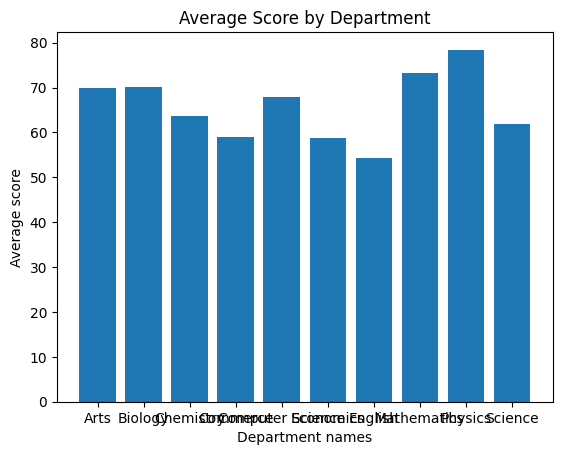

In [ ]:
average_score = school_df.groupby("department")["score"].mean()

plt.bar(average_score.index, average_score.values)

plt.xlabel("Department names")
plt.ylabel("Average score")
plt.title("Average Score by Department")

plt.show()



# Question 06: [ Marks 10 ]

Using Matplotlib, create a histogram of the score column.

* Use 10 bins
* Add a title: "Distribution of Student Scores"
* Label X-axis as "Score" and Y-axis as "Number of Students"
* Display the chart

## Answer 06:

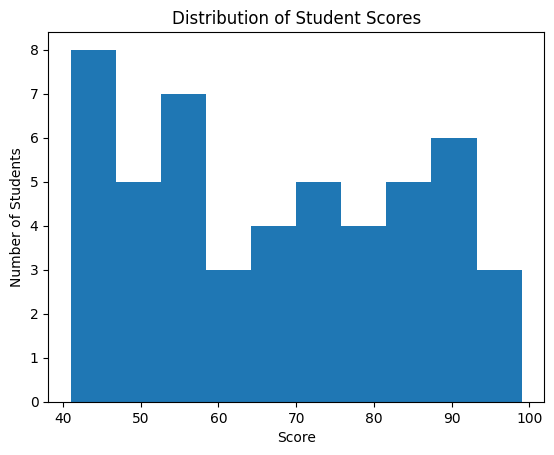

In [ ]:
plt.hist(school_df["score"], bins = 10)

plt.title("Distribution of Student Scores")
plt.xlabel("Score")
plt.ylabel("Number of Students")

plt.show()



# Question 07: [ Marks 10 ]

Using Matplotlib, create a scatter plot to visualize the relationship between attendance and score.

* X-axis: Attendance (%)
* Y-axis: Score
* Add a title: "Attendance vs Score"
* Label both axes properly
* Display the chart

## Answer 07:


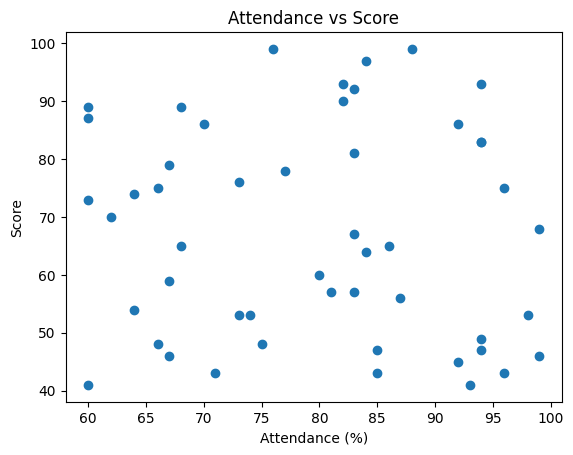

In [ ]:
plt.scatter(school_df["attendance"], school_df["score"])

plt.xlabel("Attendance (%)")
plt.ylabel("Score")
plt.title("Attendance vs Score")

plt.show()



# Question 08: [ Marks 10 ]

Using Seaborn, create a boxplot / barplot that shows the distribution of score across different grade categories.

* X-axis: Grade
* Y-axis: Score
* Add a title: "Score Distribution by Grade"
* Display the chart

## Answer 08:

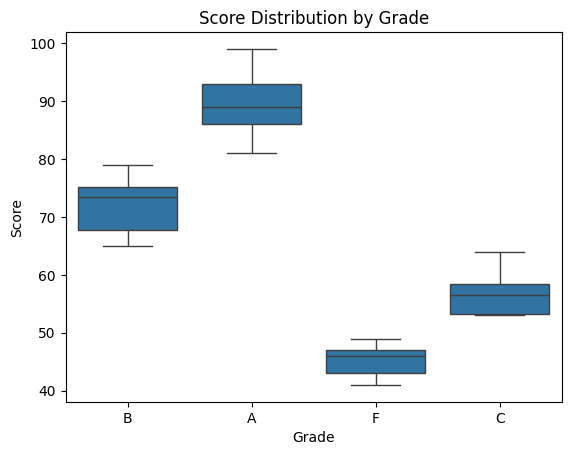

In [ ]:
sns.boxplot(data = school_df, x = "grade", y = "score")

plt.title("Score Distribution by Grade")
plt.xlabel("Grade")
plt.ylabel("Score")

plt.show()



# Question 09: [ Marks 10 ]

Using Seaborn, create a countplot showing the number of students in each department.

* Add a title: "Number of Students per Department"
* Display the chart

# Write Answer 09:

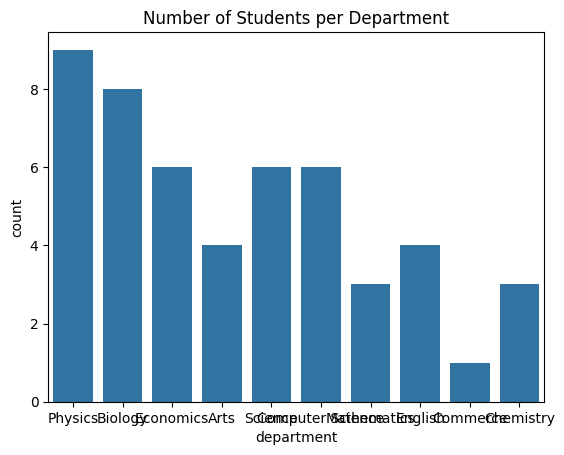

In [ ]:
sns.countplot(data = school_df, x = "department")

plt.title("Number of Students per Department")

plt.show()



# Question 10: [ Marks 10 ]

create a scatter plot showing attendance vs score.

* Color the points by department
* Add a title: "Attendance vs Score by Department"
* Label X-axis as "Attendance (%)" and Y-axis as "Score"
* Display the chart

# Write Answer 10:

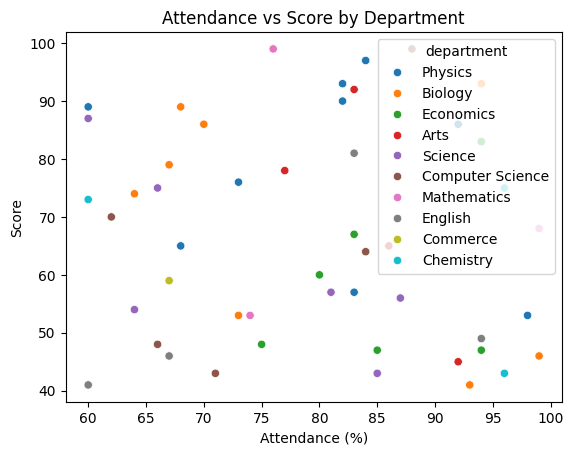

In [ ]:
sns.scatterplot(data = school_df, x = "attendance", y = "score", hue = "department")

plt.title("Attendance vs Score by Department")
plt.xlabel("Attendance (%)")
plt.ylabel("Score")

plt.show()

